In [38]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [14]:
data = pd.read_csv("../data/careflow_ed_event_log_as_is.csv")
data

,Case_ID,Activity_Name,Timestamp,Department,Resource,Waiting_Time_Min,Duration_Min,Patient_Type,Triage_Level,Event_Sequence,Is_Revisit,Loop_Back_Flag,Outcome,Scenario,Data_Origin
0,ED-00001,Registration,2026-01-01 00:59:23,Registration,REG-01,0.00,2.80,Walk-in,3,1,0,1,Discharged,AS-IS,SIMULATED
1,ED-00001,Triage,2026-01-01 01:13:13,Triage,TN-01,11.03,2.53,Walk-in,3,2,0,1,Discharged,AS-IS,SIMULATED
2,ED-00001,Doctor Consultation,2026-01-01 02:15:47,Emergency Medicine,DR-05,60.03,13.67,Walk-in,3,3,0,1,Discharged,AS-IS,SIMULATED
3,ED-00001,Lab Test,2026-01-01 02:38:37,Laboratory,LT-03,9.17,6.60,Walk-in,3,4,0,1,Discharged,AS-IS,SIMULATED
4,ED-00001,Lab Result Received,2026-01-01 03:07:23,Laboratory,LT-02,22.17,1.43,Walk-in,3,5,0,1,Discharged,AS-IS,SIMULATED
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,ED-01385,Triage,2026-04-01 00:27:51,Triage,TN-03,29.05,5.87,Walk-in,5,2,0,1,Discharged,AS-IS,SIMULATED
9996,ED-01385,Doctor Consultation,2026-04-01 01:20:35,Emergency Medicine,DR-06,46.87,24.28,Walk-in,5,3,0,1,Discharged,AS-IS,SIMULATED
9997,ED-01385,Doctor Consultation,2026-04-01 02:00:04,Emergency Medicine,DR-03,15.20,8.20,Walk-in,5,4,1,1,Discharged,AS-IS,SIMULATED
9998,ED-01385,Treatment,2026-04-01 02:21:46,Emergency Medicine,TRN-02,13.50,30.00,Walk-in,5,5,0,1,Discharged,AS-IS,SIMULATED


In [15]:
data.head()

,Case_ID,Activity_Name,Timestamp,Department,Resource,Waiting_Time_Min,Duration_Min,Patient_Type,Triage_Level,Event_Sequence,Is_Revisit,Loop_Back_Flag,Outcome,Scenario,Data_Origin
0,ED-00001,Registration,2026-01-01 00:59:23,Registration,REG-01,0.00,2.80,Walk-in,3,1,0,1,Discharged,AS-IS,SIMULATED
1,ED-00001,Triage,2026-01-01 01:13:13,Triage,TN-01,11.03,2.53,Walk-in,3,2,0,1,Discharged,AS-IS,SIMULATED
2,ED-00001,Doctor Consultation,2026-01-01 02:15:47,Emergency Medicine,DR-05,60.03,13.67,Walk-in,3,3,0,1,Discharged,AS-IS,SIMULATED
3,ED-00001,Lab Test,2026-01-01 02:38:37,Laboratory,LT-03,9.17,6.60,Walk-in,3,4,0,1,Discharged,AS-IS,SIMULATED
4,ED-00001,Lab Result Received,2026-01-01 03:07:23,Laboratory,LT-02,22.17,1.43,Walk-in,3,5,0,1,Discharged,AS-IS,SIMULATED


In [16]:
data.shape

(10000, 15)

In [17]:
data.columns

Index(['Case_ID', 'Activity_Name', 'Timestamp', 'Department', 'Resource',
       'Waiting_Time_Min', 'Duration_Min', 'Patient_Type', 'Triage_Level',
       'Event_Sequence', 'Is_Revisit', 'Loop_Back_Flag', 'Outcome', 'Scenario',
       'Data_Origin'],
      dtype='object')

In [18]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 15 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Case_ID           10000 non-null  object 
 1   Activity_Name     10000 non-null  object 
 2   Timestamp         10000 non-null  object 
 3   Department        10000 non-null  object 
 4   Resource          10000 non-null  object 
 5   Waiting_Time_Min  10000 non-null  float64
 6   Duration_Min      10000 non-null  float64
 7   Patient_Type      10000 non-null  object 
 8   Triage_Level      10000 non-null  int64  
 9   Event_Sequence    10000 non-null  int64  
 10  Is_Revisit        10000 non-null  int64  
 11  Loop_Back_Flag    10000 non-null  int64  
 12  Outcome           10000 non-null  object 
 13  Scenario          10000 non-null  object 
 14  Data_Origin       10000 non-null  object 
dtypes: float64(2), int64(4), object(9)
memory usage: 1.1+ MB


In [20]:
data.describe()

,Waiting_Time_Min,Duration_Min,Triage_Level,Event_Sequence,Is_Revisit,Loop_Back_Flag
count,10000.000000,10000.000000,10000.000000,10000.000000,10000.0000,10000.000000
mean,27.880757,12.415851,3.074400,4.325600,0.0982,0.475100
std,43.836340,13.714858,0.986084,2.424082,0.2976,0.499405
min,0.000000,0.520000,1.000000,1.000000,0.0000,0.000000
25%,5.245000,4.565000,2.000000,2.000000,0.0000,0.000000
50%,13.630000,8.270000,3.000000,4.000000,0.0000,0.000000
75%,32.900000,14.970000,4.000000,6.000000,0.0000,1.000000
max,921.820000,174.470000,5.000000,12.000000,1.0000,1.000000


In [23]:
data.isna().sum()

Case_ID             0
Activity_Name       0
Timestamp           0
Department          0
Resource            0
Waiting_Time_Min    0
Duration_Min        0
Patient_Type        0
Triage_Level        0
Event_Sequence      0
Is_Revisit          0
Loop_Back_Flag      0
Outcome             0
Scenario            0
Data_Origin         0
dtype: int64

In [26]:
data.duplicated().sum()

np.int64(0)

In [24]:
data[data.duplicated()]

,Case_ID,Activity_Name,Timestamp,Department,Resource,Waiting_Time_Min,Duration_Min,Patient_Type,Triage_Level,Event_Sequence,Is_Revisit,Loop_Back_Flag,Outcome,Scenario,Data_Origin


In [28]:
data.nunique()

Case_ID             1385
Activity_Name          9
Timestamp           9992
Department             7
Resource              31
Waiting_Time_Min    3700
Duration_Min        2263
Patient_Type           3
Triage_Level           5
Event_Sequence        12
Is_Revisit             2
Loop_Back_Flag         2
Outcome                2
Scenario               1
Data_Origin            1
dtype: int64

In [30]:
data['Case_ID'].nunique()

1385

In [31]:
data['Activity_Name'].nunique()

9

In [36]:
data['Case_ID'].value_counts()

Case_ID
ED-00029    12
ED-01333    12
ED-01133    12
ED-00694    12
ED-00172    12
            ..
ED-00060     5
ED-01341     5
ED-01338     5
ED-00874     5
ED-00871     5
Name: count, Length: 1385, dtype: int64

In [33]:
data['Activity_Name'].value_counts()

Activity_Name
Doctor Consultation    2026
Triage                 1508
Registration           1385
Treatment              1385
Discharge              1164
Lab Result Received     819
Lab Test                819
X-Ray                   673
Admission               221
Name: count, dtype: int64

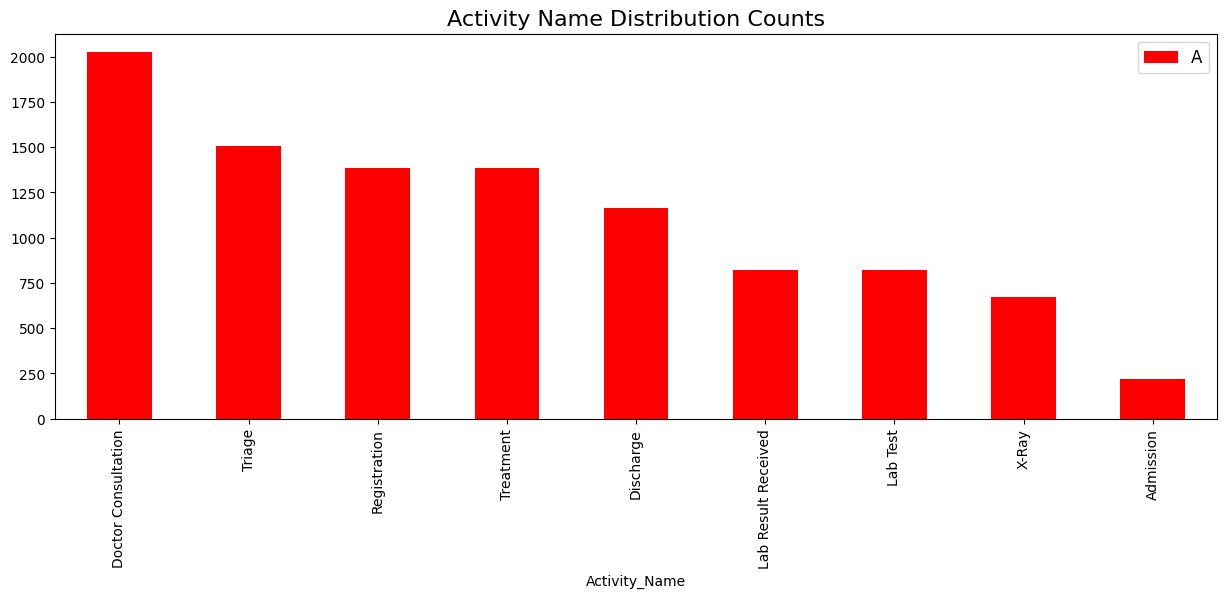

In [ ]:
data['Activity_Name'].value_counts().plot(kind='bar', figsize=(15, 5), color='red')
plt.title('Activity Name Distribution Counts', fontsize=16)
plt.show()

In [49]:
# not running it for now

# df["Timestamp"] = pd.to_datetime(
#     df["Timestamp"],
#     errors="coerce"
# )

# print("Invalid timestamps:", df["Timestamp"].isna().sum())

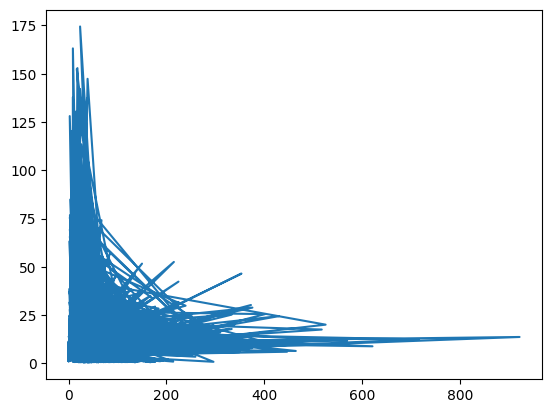

In [ ]:
plt.plot(data["Waiting_Time_Min"],data["Duration_Min"])

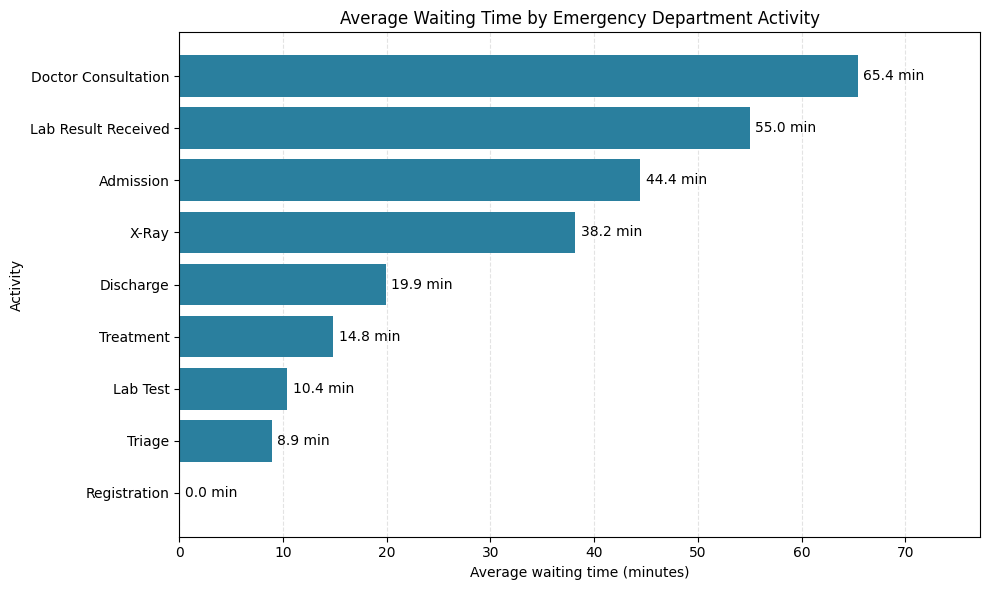

In [ ]:
mean_wait_by_activity = (
    data.groupby("Activity_Name")["Waiting_Time_Min"]
    .mean()
    .sort_values()
)

fig, ax = plt.subplots(figsize=(10, 6))
bars = ax.barh(mean_wait_by_activity.index, mean_wait_by_activity.values, color="#2a7f9e")
ax.bar_label(bars, fmt="%.1f min", padding=4)
ax.set_title("Average Waiting Time by Emergency Department Activity")
ax.set_xlabel("Average waiting time (minutes)")
ax.set_ylabel("Activity")
ax.set_xlim(0, mean_wait_by_activity.max() * 1.18)
ax.grid(axis="x", linestyle="--", alpha=0.35)
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()